# CS02 - Power sharing between a thermal plant and a solar plant (3-bus, Niamey context)

**Problem type:** power balance - who supplies the load, the role of the slack bus,
reactive power and losses.
**Source:** Travaux pratiques, case 1. Grid parameters are **fictitious and educational**
(not NIGELEC data); the solar profile is **real** (NASA POWER, Niamey, 4 May 2023).

## 1. Context
| Bus | Equipment | Power |
|---|---|---|
| 1 | Thermal power station (HFO/diesel) | slack, $|V| = 1.02$ p.u. |
| 2 | City substation | 50 MW + 20 MVAr at the evening peak |
| 3 | Solar PV plant | 30 MW peak |

Three 132 kV lines (ACSR 240/40: $0.12 + j0.39$ ohm/km, 2.9 uS/km), 15 to 25 km long,
hot-season rating 100 MVA.

## 2. Exercise
1. Are the voltages at buses 2 and 3 close to nominal?
2. Does the solar plant reduce the output of the thermal plant? By how much?
3. Is there enough reactive power? Who provides it?
4. Are the lines adequately sized?
5. What are the total active losses?
6. *(Real profile)* Over the 24 hours of the peak-demand day, how much energy does the PV
   plant supply and how does the thermal plant follow the residual demand?

## 3. Theory in three lines
* The **slack bus** fixes the angle reference and closes the power balance:
  $P_{slack} = \sum P_{load} - \sum P_{gen,other} + P_{losses}$.
  First estimate (no losses): $P_{slack} = 50 - 30 = 20$ MW.
* A **PQ** injection (PV plant at unity power factor) fixes $P$ and $Q = 0$; a **PV**
  injection (plant in voltage-control mode) fixes $P$ and $|V|$, and $Q$ follows.
* Voltage drop along a line: $\Delta V \approx (RP + XQ)/V$. On 132 kV lines $X \gg R$, so
  **reactive** flows dominate voltage drop, **active** flows dominate angles.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pscs").exists())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import pypsa
import matplotlib.pyplot as plt

import pscs
from pscs.kpi import run_pf, kpis, bus_table, branch_table, one_snapshot
from pscs.plotting import ENTITY, SERIES, CRITICAL, INK2, MUTED, save, limit_line

DATA, FIG, TAB = pscs.setup()

## 4. Load the PyPSA dataset
The dataset is a standard PyPSA CSV folder: `buses.csv`, `carriers.csv`, `generators.csv`,
`loads.csv`, `lines.csv`, plus the time series `loads-p_set.csv`, `loads-q_set.csv`,
`generators-p_set.csv` and `generators-p_max_pu.csv` (= `loads_t`, `generators_t`).

In [2]:
n = pypsa.Network(DATA / "networks" / "niamey_3bus")
print(n)
n.buses[["v_nom", "v_mag_pu_set", "description"]]

PyPSA Network 'Niamey area, 3-bus teaching network'


,v_nom,v_mag_pu_set,description
name,,,
1,132.0,1.02,Thermal power station (slack)
2,132.0,1.00,City substation
3,132.0,1.00,Solar PV plant


In [3]:
n.lines[["bus0", "bus1", "length", "r", "x", "b", "s_nom"]]

,bus0,bus1,length,r,x,b,s_nom
name,,,,,,,
L1-2,1,2,25.0,3.0,9.75,7.2500e-05,100.0
L1-3,1,3,20.0,2.4,7.80,5.8000e-05,100.0
L2-3,2,3,15.0,1.8,5.85,4.3500e-05,100.0


In [4]:
pd.concat({"PV output (MW)": n.generators_t.p_set["pv"],
           "city demand (MW)": n.loads_t.p_set["city"]}, axis=1).T.round(1)

snapshot,2023-05-04 00:00:00,2023-05-04 01:00:00,2023-05-04 02:00:00,2023-05-04 03:00:00,2023-05-04 04:00:00,2023-05-04 05:00:00,2023-05-04 06:00:00,2023-05-04 07:00:00,2023-05-04 08:00:00,2023-05-04 09:00:00,...,2023-05-04 14:00:00,2023-05-04 15:00:00,2023-05-04 16:00:00,2023-05-04 17:00:00,2023-05-04 18:00:00,2023-05-04 19:00:00,2023-05-04 20:00:00,2023-05-04 21:00:00,2023-05-04 22:00:00,2023-05-04 23:00:00
PV output (MW),0.0,0.0,0.0,0.0,0.0,0.0,0.3,3.1,7.8,13.0,...,17.9,13.8,9.4,4.3,1.2,0.0,0.0,0.0,0.0,0.0
city demand (MW),34.6,32.6,31.1,30.2,29.7,30.7,32.7,35.7,38.7,41.2,...,46.4,46.0,45.5,46.0,48.1,50.0,49.9,48.3,43.8,38.8


## 5. Design-point study (questions 1 to 5)
We take the evening-peak demand (50 MW + 20 MVAr) and assume the PV plant at full output
(30 MW), as in the exercise. Three variants of the solar plant:
* **No PV** - reference;
* **PV, unity power factor** - the default grid-code setting for small plants;
* **PV, voltage control** - the inverters hold 1.02 p.u. at bus 3 (they become a PV bus).

In [5]:
def design_point(pv_mw, mode="pq"):
    m = one_snapshot(n, n.snapshots[19])                 # 19:00, the peak hour
    m.loads_t.p_set.iloc[0, 0], m.loads_t.q_set.iloc[0, 0] = 50.0, 20.0
    m.generators_t.p_set.loc[:, "pv"] = pv_mw
    if mode == "pv":
        m.generators.loc["pv", "control"] = "PV"
        m.buses.loc["3", "v_mag_pu_set"] = 1.02
    run_pf(m)
    return m

variants = {"No PV": design_point(0), "PV 30 MW, unity PF": design_point(30),
            "PV 30 MW, voltage control": design_point(30, "pv")}
rows = {}
for name, m in variants.items():
    k = kpis(m)
    v = m.buses_t.v_mag_pu.iloc[0]
    rows[name] = {"|V2| (p.u.)": v["2"], "|V3| (p.u.)": v["3"],
                  "thermal P (MW)": m.generators_t.p.iloc[0]["thermal"],
                  "thermal Q (MVAr)": m.generators_t.q.iloc[0]["thermal"],
                  "PV Q (MVAr)": m.generators_t.q.iloc[0]["pv"],
                  "max loading (%)": k["max loading (%)"], "losses (MW)": k["losses (MW)"]}
design = pd.DataFrame(rows).T
design.to_csv(TAB / "cs02_design_point.csv")
design.round(3)

,|V2| (p.u.),|V3| (p.u.),thermal P (MW),thermal Q (MVAr),PV Q (MVAr),max loading (%),losses (MW)
No PV,1.009,1.014,50.280,17.790,0.000,31.317,0.280
"PV 30 MW, unity PF",1.011,1.017,20.192,17.496,0.000,31.930,0.192
"PV 30 MW, voltage control",1.013,1.020,20.180,5.733,11.713,33.196,0.180


In [6]:
branch_table(variants["PV 30 MW, unity PF"])[["from", "to", "P_from (MW)", "Q_from (MVAr)",
                                              "loss (MW)", "|S| (MVA)", "loading (%)"]].round(2)

,from,to,P_from (MW),Q_from (MVAr),loss (MW),|S| (MVA),loading (%)
name,,,,,,,
L1-2,1,2,19.30,10.46,0.08,22.40,22.40
L1-3,1,3,0.89,7.03,0.01,8.10,8.10
L2-3,2,3,-30.78,-8.50,0.10,31.93,31.93


**Answers** (the numbers are printed from the results above)

In [7]:
d = design
print(f"""1. Voltages: |V2| = {d.loc['No PV','|V2| (p.u.)']:.3f} p.u. without PV and {d.loc['PV 30 MW, unity PF','|V2| (p.u.)']:.3f} with PV
   (slack at 1.02): close to nominal, inside 0.95-1.05. The city bus is the lowest point.
2. Thermal output: {d.loc['No PV','thermal P (MW)']:.2f} MW without PV, {d.loc['PV 30 MW, unity PF','thermal P (MW)']:.2f} MW with 30 MW of PV.
   The estimate 50 - 30 = 20 MW is right; the difference is the losses.
3. Reactive power: at unity PF the thermal plant gives {d.loc['PV 30 MW, unity PF','thermal Q (MVAr)']:.1f} MVAr (city 20 MVAr minus the
   net line charging). In voltage-control mode the PV inverters give {d.loc['PV 30 MW, voltage control','PV Q (MVAr)']:.1f} MVAr and the
   thermal plant only {d.loc['PV 30 MW, voltage control','thermal Q (MVAr)']:.1f} MVAr. A 30 MW plant with ~33 MVA of inverters can
   supply sqrt(33^2-30^2) = {np.sqrt(33**2-30**2):.1f} MVAr at full output: the request is feasible.
4. Lines: maximum loading {d['max loading (%)'].max():.0f} % of the 100 MVA hot-season rating: adequate.
5. Active losses: {d.loc['No PV','losses (MW)']:.2f} MW without PV ({100*d.loc['No PV','losses (MW)']/50:.1f} % of demand),
   {d.loc['PV 30 MW, unity PF','losses (MW)']:.2f} MW with PV: generation closer to the load means less transport.""")

1. Voltages: |V2| = 1.009 p.u. without PV and 1.011 with PV
   (slack at 1.02): close to nominal, inside 0.95-1.05. The city bus is the lowest point.
2. Thermal output: 50.28 MW without PV, 20.19 MW with 30 MW of PV.
   The estimate 50 - 30 = 20 MW is right; the difference is the losses.
3. Reactive power: at unity PF the thermal plant gives 17.5 MVAr (city 20 MVAr minus the
   net line charging). In voltage-control mode the PV inverters give 11.7 MVAr and the
   thermal plant only 5.7 MVAr. A 30 MW plant with ~33 MVA of inverters can
   supply sqrt(33^2-30^2) = 13.7 MVAr at full output: the request is feasible.
4. Lines: maximum loading 33 % of the 100 MVA hot-season rating: adequate.
5. Active losses: 0.28 MW without PV (0.6 % of demand),
   0.19 MW with PV: generation closer to the load means less transport.


## 6. A real day: 24 AC load flows with the measured solar profile (question 6)
PyPSA runs one Newton-Raphson load flow per snapshot: `n.pf()` solves the 24 hours at once.

In [8]:
run_pf(n)
day = pd.DataFrame({
    "demand (MW)": n.loads_t.p.sum(axis=1),
    "PV (MW)": n.generators_t.p["pv"],
    "thermal (MW)": n.generators_t.p["thermal"],
    "losses (MW)": (n.lines_t.p0 + n.lines_t.p1).sum(axis=1),
    "|V2| (p.u.)": n.buses_t.v_mag_pu["2"],
    "|V3| (p.u.)": n.buses_t.v_mag_pu["3"],
})
day.index = day.index.hour
day.to_csv(TAB / "cs02_day.csv")
energy = day[["demand (MW)", "PV (MW)", "thermal (MW)", "losses (MW)"]].sum()
print("Daily energy (MWh):"); print(energy.round(1))
print("PV share of demand: %.1f %%" % (100 * energy["PV (MW)"] / energy["demand (MW)"]))
day.round(3)

Daily energy (MWh):
demand (MW)     980.3
PV (MW)         146.9
thermal (MW)    837.4
losses (MW)       4.1
dtype: float64
PV share of demand: 15.0 %


,demand (MW),PV (MW),thermal (MW),losses (MW),|V2| (p.u.),|V3| (p.u.)
snapshot,,,,,,
0,34.555,0.000,34.687,0.132,1.013,1.016
1,32.601,0.000,32.718,0.117,1.013,1.016
2,31.145,0.000,31.252,0.107,1.013,1.016
3,30.182,0.000,30.282,0.100,1.014,1.016
4,29.711,0.000,29.807,0.097,1.014,1.017
5,30.720,0.000,30.823,0.104,1.013,1.016
6,32.719,0.326,32.510,0.117,1.013,1.016
7,35.710,3.107,32.732,0.129,1.012,1.016
8,38.696,7.774,31.059,0.138,1.012,1.016


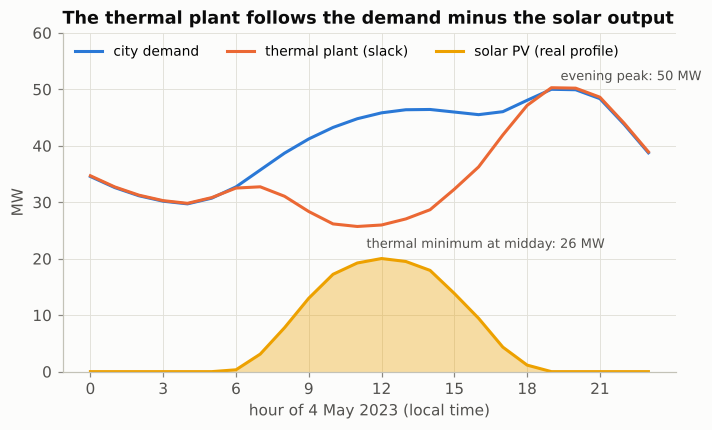

In [9]:
fig, ax = plt.subplots(figsize=(7.2, 4.0))
ax.plot(day.index, day["demand (MW)"], color=ENTITY["demand"], label="city demand")
ax.plot(day.index, day["thermal (MW)"], color=ENTITY["thermal"], label="thermal plant (slack)")
ax.fill_between(day.index, 0, day["PV (MW)"], color=ENTITY["solar"], alpha=0.35, lw=0)
ax.plot(day.index, day["PV (MW)"], color=ENTITY["solar"], label="solar PV (real profile)")
for col, y, txt in [(ENTITY["demand"], day["demand (MW)"].max(), "evening peak"),
                    (ENTITY["thermal"], day["thermal (MW)"].min(), "thermal minimum at midday")]:
    h = (day["demand (MW)"] if txt == "evening peak" else day["thermal (MW)"]).idxmax() \
        if txt == "evening peak" else day["thermal (MW)"].idxmin()
    ax.annotate(f"{txt}: {y:.0f} MW", (h, y), xytext=(6, 6 if txt == 'evening peak' else -14),
                textcoords="offset points", fontsize=8.5, color=INK2)
ax.set_xlabel("hour of 4 May 2023 (local time)"); ax.set_ylabel("MW")
ax.set_xticks(range(0, 24, 3)); ax.set_ylim(0, 60)
ax.set_title("The thermal plant follows the demand minus the solar output")
ax.legend(loc="upper left", ncol=3)
save(fig, FIG / "cs02_day_balance.png")
fig

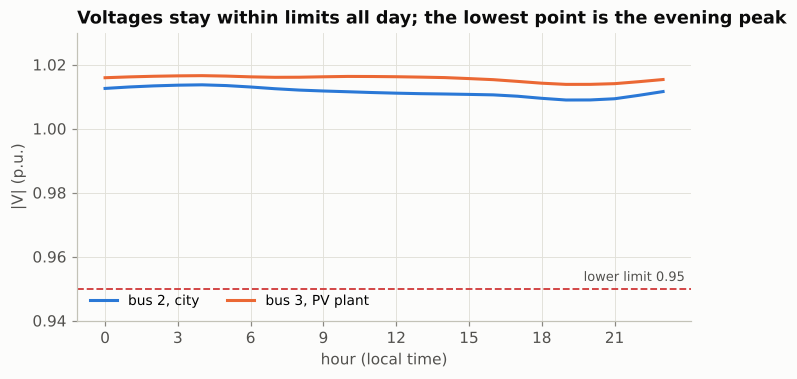

In [10]:
fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.plot(day.index, day["|V2| (p.u.)"], color=SERIES[0], label="bus 2, city")
ax.plot(day.index, day["|V3| (p.u.)"], color=SERIES[1], label="bus 3, PV plant")
limit_line(ax, 0.95, "lower limit 0.95", color=CRITICAL)
ax.set_ylim(0.94, 1.03); ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("hour (local time)"); ax.set_ylabel("|V| (p.u.)")
ax.set_title("Voltages stay within limits all day; the lowest point is the evening peak")
ax.legend(loc="lower left", ncol=2)
save(fig, FIG / "cs02_day_voltages.png")
fig

## 7. Interpretation
* On this hot, hazy peak day the PV plant (30 MW) produces at most about 20 MW and covers
  about 15 % of the daily energy. It covers part of the **day-time** demand, but the **peak is in the evening**
  (19:00-21:00), when the sun has set: the thermal plant must still be sized for the full
  peak. PV saves fuel (energy) but, without storage, does not reduce the capacity needed.
* The thermal plant must **ramp** down at midday and up in the late afternoon (a steep ramp
  between 16:00 and 19:00). This "duck curve" shape grows with more solar.
* Voltages and line loadings are comfortable in this small, short network: the problem
  here is **energy and flexibility**, not the grid. The next cases add distance (CS03) and
  meshing (CS04-CS06), where the grid becomes the constraint.

**What to say:** "In this first case I study a three-bus grid to understand how the load is
shared between conventional and solar generation. The load flow gives the nodal voltages,
the line flows and the losses. Solar reduces the thermal output by up to 30 MW (20 MW on the
real peak day) and reduces the losses, but the evening peak remains entirely on the thermal plant."

In [11]:
pscs.save_summary("cs02", {
    "thermal_noPV": design.loc["No PV", "thermal P (MW)"],
    "thermal_PV": design.loc["PV 30 MW, unity PF", "thermal P (MW)"],
    "loss_noPV": design.loc["No PV", "losses (MW)"],
    "loss_PV": design.loc["PV 30 MW, unity PF", "losses (MW)"],
    "V2_noPV": design.loc["No PV", "|V2| (p.u.)"], "V2_PV": design.loc["PV 30 MW, unity PF", "|V2| (p.u.)"],
    "Q_pv_voltage_control": design.loc["PV 30 MW, voltage control", "PV Q (MVAr)"],
    "max_loading": design["max loading (%)"].max(),
    "day_demand_MWh": energy["demand (MW)"], "day_pv_MWh": energy["PV (MW)"],
    "day_thermal_MWh": energy["thermal (MW)"], "pv_share": energy["PV (MW)"] / energy["demand (MW)"],
    "thermal_min_MW": day["thermal (MW)"].min(), "thermal_max_MW": day["thermal (MW)"].max(),
})